In [ ]:
# Project 1: Weather Forecast Web API Pipeline
## This notebook demonstrates the end-to-end data pipeline: geocoding a location, fetching live weather forecasts via Open-Meteo with robust exponential backoff, parsing the response into a `pandas` DataFrame, and visualizing temperature trends using `matplotlib`.

In [1]:
import sys
from pathlib import Path

# Add the project root directory to Python's path so we can import from src/
root_dir = Path().resolve().parent
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

import pandas as pd
import matplotlib.pyplot as plt
from src.weather_client import geocode_location, get_forecast, process_forecast_to_dataframe

# Define contact email for polite User-Agent headers
CONTACT_EMAIL = "b35465@students.ucu.ac.ug"

In [2]:
# 1. Geocode a target location
location_query = "Kampala"
print(f"Searching coordinates for '{location_query}'...")
locations = geocode_location(location_query, contact_email=CONTACT_EMAIL)

loc = locations[0]
lat, lon = loc["latitude"], loc["longitude"]
print(f"Found: {loc['name']}, {loc.get('country', '')} (Lat: {lat}, Lon: {lon})")

# 2. Fetch a 7-day forecast
print("Fetching weather forecast...")
raw_forecast = get_forecast(lat, lon, days=7, contact_email=CONTACT_EMAIL)
print("Forecast data successfully retrieved!")

Searching coordinates for 'Kampala'...
Found: Kampala, Uganda (Lat: 0.31628, Lon: 32.58219)
Fetching weather forecast...
Forecast data successfully retrieved!


In [3]:
# Convert raw JSON data into a clean pandas DataFrame
df_forecast = process_forecast_to_dataframe(raw_forecast)

print("\nProcessed 7-Day Weather Forecast:")
display(df_forecast)


Processed 7-Day Weather Forecast:


,Date,Weather Code,Max Temp (°C),Min Temp (°C),Precipitation (mm),Max Wind Speed (km/h),Condition
0,2026-10-21,81,27.9,18.5,4.4,7.8,Unknown code (81)
1,2026-10-22,51,27.0,19.8,0.3,14.6,Light drizzle
2,2026-10-23,81,26.2,19.3,5.3,12.9,Unknown code (81)
3,2026-10-24,81,26.7,19.1,7.2,13.1,Unknown code (81)
4,2026-10-25,53,25.8,18.9,2.7,8.7,Moderate drizzle
5,2026-10-26,55,26.2,18.5,5.4,8.1,Dense drizzle
6,2026-10-27,53,26.7,18.6,5.4,9.1,Moderate drizzle


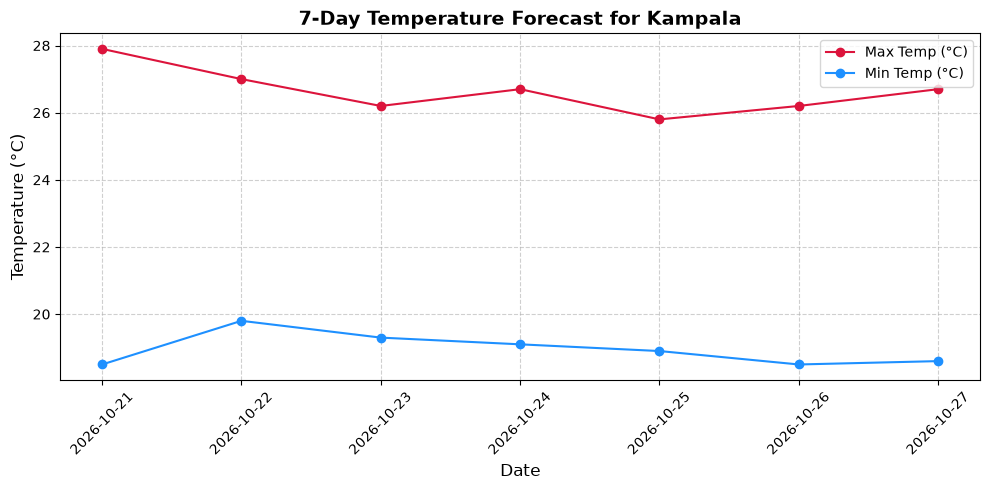

In [4]:
# Plot temperature trends
plt.figure(figsize=(10, 5))
plt.plot(df_forecast["Date"], df_forecast["Max Temp (°C)"], marker='o', color='crimson', label='Max Temp (°C)')
plt.plot(df_forecast["Date"], df_forecast["Min Temp (°C)"], marker='o', color='dodgerblue', label='Min Temp (°C)')

plt.title(f"7-Day Temperature Forecast for {loc['name']}", fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=12)
plt.ylabel("Temperature (°C)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
## AI Usage Declaration
##In compliance with academic integrity guidelines, generative AI tools were consulted during the structural design of this code (specifically for implementing robust exponential backoff error-handling patterns). All code has been independently reviewed, tested with `pytest`, and understood for viva examination.